# Wyszukiwanie trójkąta zawierającego punkt

Notebook buduje triangulację, wyszukuje trójkąt dla wskazanych współrzędnych i wizualizuje wynik.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from Projekt.delaunay import Triangulation

In [17]:
points = np.array([
    [6.42647586, -8.53769683], [1.50583384, 2.0546824],
    [1.97936182, 5.52998142], [-1.01798849, -6.93659749],
    [5.3814328, -2.66880444], [-8.62529473, -6.77310924],
])
triangulation = Triangulation(points, variant="Graph")
triangulation.triangulate()
triangles = triangulation.get_triangulation()
triangles

Dodawanie punktu 0: [ 6.42647586 -8.53769683]
Dodawanie punktu 1: [1.50583384 2.0546824 ]
Dodawanie punktu 2: [1.97936182 5.52998142]
Dodawanie punktu 3: [-1.01798849 -6.93659749]
Dodawanie punktu 4: [ 5.3814328  -2.66880444]
Dodawanie punktu 5: [-8.62529473 -6.77310924]


[(2, 1, 4), (0, 4, 3), (1, 3, 4), (3, 5, 0), (2, 5, 1), (3, 1, 5)]

In [18]:
query_points = np.array([[0.0, -5.0], [2.0, 2.0], [-5.0, -5.0]])
found = []
for query in query_points:
    triangle_id, triangle, visited = triangulation.find_triangle(query, variant="JaW", trace=True)
    found.append((query, triangle_id, triangle))
    print(f"Punkt {query} znajduje się w trójkącie {triangle_id}: {triangle}")
    print(f"Odwiedzona ścieżka: {visited}")

Punkt [ 0. -5.] znajduje się w trójkącie 27: (1, 3, 4)
Odwiedzona ścieżka: [25, 35, 36, 27]
Punkt [2. 2.] znajduje się w trójkącie 25: (2, 1, 4)
Odwiedzona ścieżka: [25]
Punkt [-5. -5.] znajduje się w trójkącie 36: (3, 1, 5)
Odwiedzona ścieżka: [25, 35, 36]


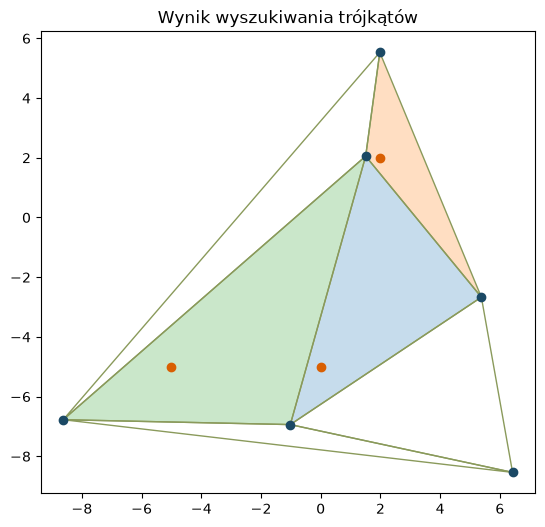

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
for triangle in triangles:
    polygon = points[list(triangle)]
    polygon = np.vstack((polygon, polygon[0]))
    ax.plot(polygon[:, 0], polygon[:, 1], color="#8a9a5b", linewidth=1)
for query, triangle_id, triangle in found:
    polygon = points[list(triangle)]
    polygon = np.vstack((polygon, polygon[0]))
    ax.fill(polygon[:, 0], polygon[:, 1], alpha=0.25)
    ax.scatter(*query, color="#d95f02", zorder=3)
ax.scatter(points[:, 0], points[:, 1], color="#1b4965", zorder=2)
ax.set_aspect("equal")
ax.set_title("Wynik wyszukiwania trójkątów")
plt.show()